# UTS IN0417 - Paket A: Student Performance in Exams (Regression)
Nama : Nabil Faiq Aflah
NIM  : 261636002

In [1]:
NIM = "261636002"
PAKET = "A"
RANDOM_STATE = int(NIM[-3:])
if RANDOM_STATE == 0:
    RANDOM_STATE = 42
print(NIM, PAKET, RANDOM_STATE)

261636002 A 2


## 2. Import library dan load data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv("StudentsPerformance.csv")   # sesuaikan nama file jika berbeda
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 3. Data understanding

In [3]:
print("Ukuran dataset:", df.shape)
print("Nama kolom:", list(df.columns))
df.info()                      # tipe data tiap kolom
print(df.isnull().sum())       # jumlah missing value per kolom
print("Duplikat:", df.duplicated().sum())
df.describe()                  # ringkasan statistik kolom numerik

Ukuran dataset: (1000, 8)
Nama kolom: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 43.0 KB
gender                         0
race/ethnicity                 0
parental level of education    0
lunch             

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [4]:
# Target: math score (kontinu)
print(df["math score"].describe())

# Kolom kategorikal: lihat nilai uniknya
kolom_kategorikal = ["gender", "race/ethnicity", "parental level of education",
                     "lunch", "test preparation course"]
for k in kolom_kategorikal:
    print(df[k].value_counts(), "\n")

count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64
gender
female    518
male      482
Name: count, dtype: int64 

race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64 

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64 

lunch
standard        645
free/reduced    355
Name: count, dtype: int64 

test preparation course
none         642
completed    358
Name: count, dtype: int64 



**Temuan data understanding** (lengkapi dengan kata-katamu sendiri dari output di atas):
- Kolom numerik: math score, reading score, writing score. Kolom kategorikal: gender, race/ethnicity, parental level of education, lunch, test preparation course.
- Missing value: [isi dari output]
- Fitur yang dipakai: model sederhana (reading + writing), model lengkap (semua fitur).

## 4. Preprocessing

In [5]:
# Linear Regression hanya menerima angka, jadi kolom kategorikal diubah
# menjadi kolom 0/1 (one-hot encoding). drop_first=True membuang satu kategori
# per kolom agar tidak ada kolom yang redundan (kategori yang dibuang menjadi
# pembanding/baseline).
y = df["math score"]
X_full = pd.get_dummies(df.drop(columns=["math score"]),
                        columns=kolom_kategorikal, drop_first=True, dtype=int)
print(X_full.shape)
X_full.head()

(1000, 14)


,reading score,writing score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,72,74,0,1,0,0,0,1,0,0,0,0,1,1
1,90,88,0,0,1,0,0,0,0,0,1,0,1,0
2,95,93,0,1,0,0,0,0,0,1,0,0,1,1
3,57,44,1,0,0,0,0,0,0,0,0,0,0,1
4,78,75,1,0,1,0,0,0,0,0,1,0,1,1


**Penjelasan preprocessing** (tulis dengan bahasamu sendiri):
- Target `math score` dipisah dari fitur.
- Kolom kategorikal diubah dengan one-hot encoding (drop_first=True) karena Linear Regression hanya menerima angka.
- [Tambahkan: apakah ada missing value/duplikat yang perlu ditangani, berdasarkan outputmu.]

## 5. Train-test split

In [6]:
# Split SEKALI pada X_full, sehingga model sederhana dan lengkap
# memakai baris train/test yang sama.
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y, test_size=0.20, random_state=RANDOM_STATE
)

# Model sederhana: ambil kolom reading + writing dari hasil split yang sama
fitur_simple = ["reading score", "writing score"]
X_train_simple = X_train_full[fitur_simple]
X_test_simple = X_test_full[fitur_simple]

print(X_train_full.shape, X_test_full.shape)

(800, 14) (200, 14)


## 6. Modeling

In [7]:
model_simple = LinearRegression()
model_simple.fit(X_train_simple, y_train)   # belajar dari data train

model_full = LinearRegression()
model_full.fit(X_train_full, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## 7. Prediksi

In [8]:
# Prediksi dilakukan pada data test (data yang belum dilihat model)
y_pred_simple = model_simple.predict(X_test_simple)
y_pred_full = model_full.predict(X_test_full)

## 8. Evaluasi: MAE dan R2

In [9]:
# MAE = rata-rata selisih absolut antara nilai aktual dan prediksi (satuan: poin nilai)
mae_simple = mean_absolute_error(y_test, y_pred_simple)
mae_full = mean_absolute_error(y_test, y_pred_full)

tabel_mae = pd.DataFrame({
    "Model": ["Sederhana (reading+writing)", "Lengkap (semua fitur)"],
    "MAE": [mae_simple, mae_full],
})
print(tabel_mae)
print("Selisih MAE (sederhana - lengkap):", mae_simple - mae_full)

                         Model       MAE
0  Sederhana (reading+writing)  7.500192
1        Lengkap (semua fitur)  4.460867
Selisih MAE (sederhana - lengkap): 3.0393249062351533


In [10]:
# R2 = proporsi variasi math score yang bisa dijelaskan oleh model (maks. 1)
r2_simple = r2_score(y_test, y_pred_simple)
r2_full = r2_score(y_test, y_pred_full)

tabel_r2 = pd.DataFrame({
    "Model": ["Sederhana (reading+writing)", "Lengkap (semua fitur)"],
    "R2": [r2_simple, r2_full],
})
print(tabel_r2)
print("Selisih R2 (lengkap - sederhana):", r2_full - r2_simple)

                         Model        R2
0  Sederhana (reading+writing)  0.628709
1        Lengkap (semua fitur)  0.853305
Selisih R2 (lengkap - sederhana): 0.22459605942998562


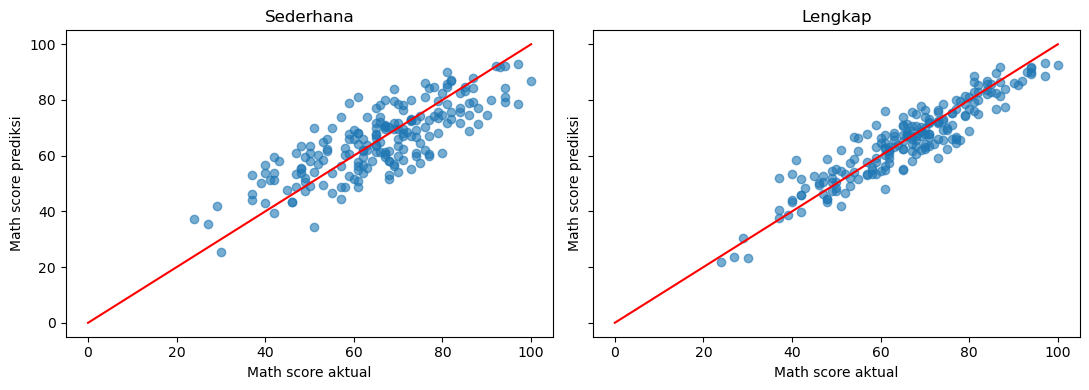

In [11]:
# Visual: aktual vs prediksi (garis merah = prediksi sempurna)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for a, pred, judul in zip(ax, [y_pred_simple, y_pred_full], ["Sederhana", "Lengkap"]):
    a.scatter(y_test, pred, alpha=0.6)
    a.plot([y.min(), y.max()], [y.min(), y.max()], color="red")
    a.set_title(judul)
    a.set_xlabel("Math score aktual")
    a.set_ylabel("Math score prediksi")
plt.tight_layout()
plt.show()

In [12]:
# Koefisien model lengkap: fitur dengan nilai absolut besar paling memengaruhi prediksi
koef = pd.Series(model_full.coef_, index=X_full.columns)
koef.reindex(koef.abs().sort_values(ascending=False).index)

gender_male                                      13.060235
race/ethnicity_group E                            4.983387
test preparation course_none                      3.369406
lunch_standard                                    3.154383
parental level of education_master's degree      -2.007808
parental level of education_bachelor's degree    -1.186591
parental level of education_high school           0.718528
writing score                                     0.682366
race/ethnicity_group B                            0.347135
parental level of education_some high school      0.342414
reading score                                     0.287053
race/ethnicity_group D                           -0.279882
race/ethnicity_group C                            0.218904
parental level of education_some college         -0.098343
dtype: float64

## 9. Interpretasi hasil

**Arti MAE dan R².**
Pada model sederhana (reading + writing), MAE sebesar 7,50 artinya prediksi math score
rata-rata meleset sekitar 7,5 poin dari nilai asli. Pada model lengkap, MAE turun menjadi
4,46 poin. R² model sederhana adalah 0,6287, artinya model menjelaskan sekitar 63% variasi
math score. R² model lengkap adalah 0,8533, artinya model menjelaskan sekitar 85% variasi.

**Perbandingan model.**
Model lengkap lebih baik daripada model sederhana. MAE turun 3,04 poin (sekitar 40% dari
MAE model sederhana) dan R² naik 0,2246. Kedua metrik menunjukkan arah yang sama, sehingga
kesimpulan ini cukup kuat. Menurut saya tambahan fitur kategorikal sepadan karena
perbaikannya besar, sedangkan biaya tambahannya hanya proses one-hot encoding.
Meski begitu, reading dan writing saja sudah cukup informatif (R² 0,63).
Fitur yang paling berpengaruh pada model lengkap: **[ISI SENDIRI dari output koefisien]**.

**Plot aktual vs prediksi.**
**[ISI SENDIRI setelah melihat plotmu: apakah titik model lengkap lebih rapat ke garis merah
daripada model sederhana, dan apakah ada pola meleset pada nilai rendah atau tinggi.]**

### Jawaban konseptual
**1. Mengapa confusion matrix tidak tepat untuk target kontinu?**
Confusion matrix menghitung prediksi yang sama persis dengan kelas aktual. Pada target
kontinu seperti math score, prediksi 71,3 untuk nilai asli 72 hampir pasti dianggap salah,
padahal selisihnya kecil. Hasilnya, hampir semua prediksi tampak salah dan matriks tidak
menunjukkan seberapa jauh meleset. Karena itu dipakai MAE dan R², yang mengukur besar
selisih.

**2. Jika target dipaksa menjadi kategori?**
Target dan prediksi harus diubah ke kategori dengan ambang batas yang sama, misalnya nilai
>= 60 dianggap lulus dan di bawahnya tidak lulus. Informasi yang hilang: perbedaan nilai di
dalam satu kategori (nilai 61 dan 99 sama-sama lulus), serta besar kesalahan di dekat
ambang (prediksi 59 untuk nilai asli 61 dihitung salah total padahal hanya meleset 2 poin).
Hasilnya juga bergantung pada pemilihan ambang.

## 10. Kesimpulan dan keterbatasan

**Kesimpulan.**
- Model lengkap (semua fitur) memberikan hasil terbaik dengan MAE 4,46 dan R² 0,8533,
  dibandingkan model sederhana dengan MAE 7,50 dan R² 0,6287.
- Fitur kategorikal memberi perbaikan yang jelas: MAE turun 3,04 poin dan R² naik 0,2246.
  Fitur yang paling berkontribusi: **[ISI SENDIRI dari output koefisien]**.
- Jadi, menambahkan fitur selain reading dan writing score membantu memprediksi math score
  dengan lebih akurat.

**Keterbatasan.**
- Evaluasi memakai satu kali split, sehingga hasilnya bisa berubah jika random_state berbeda.
- Linear Regression mengasumsikan hubungan linear antara fitur dan target.
- Dataset hanya berisi sekitar 1.000 baris (cek df.shape) dan berasal dari satu sumber data.
- **[Tambahkan satu keterbatasan lain yang kamu temukan sendiri.]**